# Zenn トピック分析

[fa0311/zenn-icons](https://github.com/fa0311/zenn-icons) に毎月コミットされる `metadata.json`（Zenn 全トピックのスナップショット）から、技術トピックのトレンドを読む。

## 目次

| 章 | 問い |
|---|---|
| 1. セットアップ | データロードと分析関数の定義 |
| 2. 全体像 | Zenn はどう成長しているか |
| 3. 何が伸びているか | 急上昇・成長率・加速/失速・新規登場 |
| 4. AI の牽引力 | 成長のどれだけが AI 関連か |
| 5. ケーススタディ | フロントエンド / 環境構築 / ネイティブアプリ |
| 6. ヒートマップ | 各トピックはいつ盛り上がったか |
| 7. 記事以外の指標 | スクラップ・本 |
| 8. 付録 | トピック検索・関数リファレンス |

## データの読み方（重要な注意）

- **タグ付けベース**: 記事は複数タグを持てるため、トピック横断の合計は記事数そのものではなく「記事×トピックのタグ付け数」
- **間隔が不均一**: スナップショットは概ね月次だが欠落がある（2025-03→2025-06）。比較は「1日あたり増加数」に正規化する
- **トピックの統合**: Zenn 側でトピックが統合されることがある（例: 2026年2〜3月に `llm` → `大規模言語モデル`）。1章の `TAG_MERGES` で検出・補正して連続な時系列にしてある。それでも急な段差を見たらまず統合を疑う
- **「読みどころ」は 2026-07 時点の観察**。データ更新後は数値・順位が変わるので、グラフを正として読み直すこと


## 1. セットアップとデータロード


In [1]:
import json
import re
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib_fontja  # noqa: F401  日本語トピック名をグラフに描画するため
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# カテゴリカル8色（ライトモード・固定順）とチャートの chrome
SERIES = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
DIVERGE_UP, DIVERGE_DOWN = "#2a78d6", "#e34948"  # 発散（増減）は青↔赤
BLUES = LinearSegmentedColormap.from_list(
    "seq-blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
BLUES.set_bad(SURFACE)

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.prop_cycle": plt.cycler(color=SERIES),
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 1,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 1,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": INK,
    "axes.titlecolor": INK,
    "axes.labelcolor": INK2,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
})
pd.options.display.max_rows = 100


In [2]:
frames = []
for path in sorted(Path("data").glob("*.json")):
    snap = pd.DataFrame.from_dict(json.loads(path.read_text()), orient="index")
    snap["date"] = pd.Timestamp(path.stem)
    frames.append(snap)

long_df = pd.concat(frames, ignore_index=True)
display_names = long_df.drop_duplicates("name", keep="last").set_index("name")["displayName"]

# 日付 × トピック のマトリクス（そのスナップショットに存在しないトピックは NaN）
articles = long_df.pivot(index="date", columns="name", values="articlesCount")
taggings = long_df.pivot(index="date", columns="name", values="taggingsCount")
scraps = long_df.pivot(index="date", columns="name", values="scrapsCount")
books = long_df.pivot(index="date", columns="name", values="booksCount")
first_seen = articles.apply(pd.Series.first_valid_index)


def search_topics(keyword: str) -> pd.DataFrame:
    """トピック名・表示名にキーワードを含むトピックを最新記事数の降順で返す。"""
    kw = keyword.lower()
    hits = display_names[
        display_names.index.str.contains(kw, case=False)
        | display_names.str.contains(kw, case=False)
    ]
    latest = articles.iloc[-1].reindex(hits.index)
    return (
        pd.DataFrame({"トピック": hits, "最新記事数": latest})
        .sort_values("最新記事数", ascending=False)
        .dropna(subset=["最新記事数"])
        .astype({"最新記事数": int})
    )


print(f"スナップショット: {len(articles)}件 ({articles.index[0]:%Y-%m-%d} 〜 {articles.index[-1]:%Y-%m-%d})")
print(f"トピック数: {articles.iloc[0].notna().sum():,} → {articles.iloc[-1].notna().sum():,}")


スナップショット: 17件 (2025-01-23 〜 2026-07-01)
トピック数: 10,768 → 17,156


### タグ統合の検出と補正

Zenn 側でトピックが統合されることがあり（例: `llm` → `大規模言語モデル`）、放置すると時系列に偽の段差が出る。
id は引き継がれないため確実な自動検出はできないが、**「消滅したトピックの記事数」と「同区間の別トピックの異常な増加」の突き合わせ**で候補を検出できる。

- `detect_tag_merges()` が候補を提案する（偶然の一致が混ざるため**人力レビュー前提**。統合先が意味的に自明かで判断する）
- レビュー済みの統合は `TAG_MERGES` に登録し、旧トピックの履歴を新トピックへ合算して連続な時系列に補正する
- 検証例: em ＋ エンジニアリングマネージャー → engineeringmanager は旧記事数の和 153 が統合先の超過増加 151 とほぼ一致する
- 注意: 統合前に新旧両方のタグが付いていた記事は合算で二重計上される（誤差は小さい）


In [3]:
# 人力レビュー済みのタグ統合辞書（旧トピック → 統合先）。
# 新しいスナップショットを取り込んだら detect_tag_merges() で新規統合がないか確認して追記する。
TAG_MERGES = {
    "llm": "大規模言語モデル",
    "yaml": "yml",
    "人工知能": "ai",
    "review": "レビュー",
    "グラフ": "graph",
    "デバッグ": "debug",
    "ログ": "log",
    "macro": "マクロ",
    "コンポーネント": "component",
    "3dプリンタ": "3dプリンター",
    "dataengineering": "データエンジニアリング",
    "microservice": "マイクロサービス",
    "microsoftteams": "teams",
    "awslambda": "lambda",
    "vscodeextension": "vscode拡張機能",
    "chromeextension": "chrome拡張",
    "chrome拡張機能": "chrome拡張",
    "objectdetection": "物体検出",
    "cv": "computervision",
    "em": "engineeringmanager",
    "エンジニアリングマネージャー": "engineeringmanager",
    "nn": "ニューラルネットワーク",
    "音楽": "music",
    "c＃": "csharp",
}


def apply_tag_merges(m: pd.DataFrame, merges: dict[str, str] | None = None) -> pd.DataFrame:
    """統合辞書に従い、旧トピックの履歴を統合先へ合算して連続な時系列にする。"""
    merges = TAG_MERGES if merges is None else merges
    m = m.copy()
    for old, new in merges.items():
        if old in m.columns and new in m.columns:
            m[new] = m[[old, new]].sum(axis=1, min_count=1)
            m = m.drop(columns=old)
        elif old in m.columns:
            m = m.rename(columns={old: new})
    return m


def detect_tag_merges(min_count: int = 30, tol: float = 0.15, anomaly_min: float = 3.0) -> pd.DataFrame:
    """タグ統合の候補を検出する（人力レビュー前提）。

    各区間で「消滅（または9割減）したトピック」と「増加が平常時の anomaly_min 倍を超え、
    かつ超過増加が消滅記事数と tol 以内で一致するトピック」を突き合わせる。
    """
    m = articles_raw
    rows = []
    for i in range(2, len(m)):
        prev, cur = m.iloc[i - 1], m.iloc[i]
        lost = prev[(prev >= min_count) & (cur.isna() | (cur <= prev * 0.1))]
        lost = lost - cur.reindex(lost.index).fillna(0)
        if lost.empty:
            continue
        delta = (cur - prev.fillna(0)).dropna()
        expected = (prev - m.iloc[i - 2].fillna(0)).reindex(delta.index).fillna(0).clip(lower=0)
        excess, anomaly = delta - expected, delta / (expected + 5)
        for old, lc in lost.items():
            cand = excess.drop(old, errors="ignore")
            best = (cand - lc).abs().idxmin()
            if abs(cand[best] - lc) / lc <= tol and anomaly[best] >= anomaly_min:
                rows.append({
                    "統合日": m.index[i].date(), "旧": old, "新候補": best,
                    "旧記事数": int(lc), "候補の超過増加": int(cand[best]),
                    "異常度": round(float(anomaly[best]), 1),
                    "レビュー済み": old in TAG_MERGES,
                })
    return pd.DataFrame(rows)


articles_raw = articles
articles = apply_tag_merges(articles)
taggings, scraps, books = (apply_tag_merges(x) for x in (taggings, scraps, books))
first_seen = articles.apply(pd.Series.first_valid_index)
print(f"タグ統合を{len(TAG_MERGES)}件補正（補正前は articles_raw に保持）")

# 検出候補の確認。「レビュー済み=False」の行は偶然の一致か、未登録の新しい統合
detect_tag_merges()


タグ統合を24件補正（補正前は articles_raw に保持）


,統合日,旧,新候補,旧記事数,候補の超過増加,異常度,レビュー済み
0,2025-06-03,shortcut,adk,38,38,7.6,False
1,2025-07-01,3dプリンタ,3dプリンター,33,36,4.1,True
2,2025-07-01,dataengineering,データエンジニアリング,91,80,3.1,True
3,2025-08-18,chrome拡張機能,gpt5,45,47,9.4,True
4,2025-09-01,microservice,zennfes2025infra,37,36,7.2,True
5,2025-10-01,vscodeextension,aiagenthackathon,35,34,6.8,True
6,2025-10-01,プロジェクト管理,lambda,117,120,9.2,False
7,2025-10-01,人工知能,aci,91,92,18.4,True
8,2025-11-01,gh,vr,57,58,9.8,False
9,2025-11-01,microsoftteams,tech,77,79,3.2,True


### 分析関数

集計（ランキング）と可視化の関数をここでまとめて定義する。以降の章は呼び出しと解釈のみ。


In [4]:
def snapshot_at(months_back: int | None) -> pd.Timestamp:
    """最新から months_back ヶ月前に最も近いスナップショット日付を返す（None は最古）。"""
    if months_back is None:
        return articles.index[0]
    target = articles.index[-1] - pd.DateOffset(months=months_back)
    return min(articles.index, key=lambda d: abs(d - target))


def rising_ranking(months_back: int | None = 1, top_n: int = 20, ascending: bool = False, metric: pd.DataFrame | None = None) -> pd.DataFrame:
    """期間中の記事数の増加ランキング（ascending=True で下降ランキング）。"""
    m = articles if metric is None else metric
    start_date, end_date = snapshot_at(months_back), m.index[-1]
    days = (end_date - start_date).days
    delta = (m.loc[end_date] - m.loc[start_date].fillna(0)).dropna()
    rank = pd.DataFrame({
        "トピック": display_names.reindex(delta.index),
        "開始時": m.loc[start_date].reindex(delta.index).fillna(0).astype(int),
        "最新": m.loc[end_date].reindex(delta.index).astype(int),
        "増加数": delta.astype(int),
        "増加数/日": (delta / days).round(2),
    }).sort_values("増加数", ascending=ascending).head(top_n)
    rank.attrs["period"] = f"{start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}（{days}日間）"
    return rank


def growth_ranking(months_back: int | None = 3, min_start: int = 50, top_n: int = 20, ascending: bool = False) -> pd.DataFrame:
    """相対成長率（%）ランキング。開始時に min_start 記事以上あるトピックが対象。"""
    start_date, end_date = snapshot_at(months_back), articles.index[-1]
    start, end = articles.loc[start_date], articles.loc[end_date]
    growth = ((end - start) / start * 100)[(start >= min_start) & end.notna()].dropna()
    rank = pd.DataFrame({
        "トピック": display_names.reindex(growth.index),
        "開始時": start.reindex(growth.index).astype(int),
        "最新": end.reindex(growth.index).astype(int),
        "成長率%": growth.round(1),
    }).sort_values("成長率%", ascending=ascending).head(top_n)
    rank.attrs["period"] = f"{start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}（開始時{min_start}記事以上）"
    return rank


def momentum_ranking(top_n: int = 15, ascending: bool = False) -> pd.DataFrame:
    """直近区間と前区間の増加ペース（/日）を比較した加速ランキング。"""
    d0, d1, d2 = articles.index[-3], articles.index[-2], articles.index[-1]
    rate_prev = (articles.loc[d1] - articles.loc[d0]) / (d1 - d0).days
    rate_now = (articles.loc[d2] - articles.loc[d1]) / (d2 - d1).days
    accel = (rate_now - rate_prev).dropna()
    rank = pd.DataFrame({
        "トピック": display_names.reindex(accel.index),
        "前区間/日": rate_prev.reindex(accel.index).round(2),
        "直近/日": rate_now.reindex(accel.index).round(2),
        "加速": accel.round(2),
    }).sort_values("加速", ascending=ascending).head(top_n)
    rank.attrs["period"] = f"前区間 {d0:%Y-%m-%d}→{d1:%Y-%m-%d} / 直近 {d1:%Y-%m-%d}→{d2:%Y-%m-%d}"
    return rank


def newcomer_ranking(months_back: int | None = 3, top_n: int = 20) -> pd.DataFrame:
    """期間中に初登場したトピックを最新記事数の多い順に返す。"""
    start_date = snapshot_at(months_back)
    new = first_seen[first_seen > start_date]
    rank = pd.DataFrame({
        "トピック": display_names.reindex(new.index),
        "初登場": new.dt.strftime("%Y-%m"),
        "最新記事数": articles.iloc[-1].reindex(new.index).fillna(0).astype(int),
    }).sort_values("最新記事数", ascending=False).head(top_n)
    rank.attrs["period"] = f"{start_date:%Y-%m-%d} 以降に初登場"
    return rank


In [5]:
def plot_topics(topics: list[str], rate: bool = False, normalize: bool = False,
                metric: pd.DataFrame | None = None, title: str | None = None,
                ylabel: str | None = None, ax=None, legend: bool = True,
                min_base: int = 20) -> None:
    """指定トピックの推移を折れ線で比較する（最大8トピック）。

    rate=True      : スナップショット間の1日あたり増加数（勢いの比較）
    normalize=True : 指数表示（規模が違うトピックの比較）。母数が小さい時点を基準にすると
                     指数が暴れるため、全トピックが min_base 以上になった最初の時点を 100 とする。
                     それでも最終値の開きが30倍を超える場合は対数軸に自動で切り替える
    metric         : articles 以外のマトリクス（taggings / scraps / share など）
    ax             : small multiples 用の描画先 Axes
    """
    m = articles if metric is None else metric
    if missing := [t for t in topics if t not in m.columns]:
        raise KeyError(f"存在しないトピック: {missing}（search_topics() で探せます）")
    if len(topics) > len(SERIES):
        raise ValueError(f"一度に比較できるのは{len(SERIES)}トピックまでです")

    sub = m[list(topics)]
    if rate:
        sub = sub.diff().div(sub.index.to_series().diff().dt.days, axis=0)
        default_ylabel, default_title = "増加数/日", "トピック別 記事数の増加ペース"
    elif normalize:
        ok = (sub >= min_base).all(axis=1)
        base = ok.idxmax() if ok.any() else max(sub[t].first_valid_index() for t in topics)
        sub = (sub / sub.loc[base] * 100).loc[base:]
        finals = sub.iloc[-1].dropna()
        log_scale = finals.max() > 30 * max(finals.min(), 1)
        default_ylabel = f"指数（{base:%Y-%m-%d} = 100" + ("、対数）" if log_scale else "）")
        default_title = "トピック別 相対成長"
    else:
        default_ylabel, default_title = "記事数", "トピック別 記事数の推移"

    own_fig = ax is None
    if own_fig:
        _, ax = plt.subplots()
    span = (sub.max().max() - min(0, sub.min().min())) or 1
    labeled: list[float] = []
    for color, topic in zip(SERIES, topics):
        s = sub[topic].dropna()
        if s.empty:
            continue
        ax.plot(s.index, s.values, color=color, label=display_names.get(topic, topic),
                marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
        v = s.iloc[-1]
        # 系列が少なく、既存ラベルと重ならないときだけ終端に値を直接ラベル
        if own_fig and len(topics) <= 4 and all(abs(v - u) > 0.05 * span for u in labeled):
            ax.annotate(f" {v:,.0f}" if v >= 100 else f" {v:,.1f}", (s.index[-1], v),
                        color=INK2, fontsize=9, va="center")
            labeled.append(v)
    locator = mdates.AutoDateLocator(maxticks=10 if own_fig else 6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    if legend:
        ax.legend(frameon=False, labelcolor=INK2, fontsize=9)
    ax.set_ylabel(ylabel or default_ylabel)
    if normalize and log_scale:
        ax.set_yscale("log")
    else:
        ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
    ax.set_title(title or default_title, fontsize=11)
    ax.margins(x=0.06)
    if own_fig:
        plt.show()


def compare_topics(topics: list[str], title: str | None = None,
                   metric: pd.DataFrame | None = None) -> None:
    """絶対数（左）と相対成長の指数（右）をセットで表示する。比較の基本形。"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
    plot_topics(topics, metric=metric, ax=ax1, title="記事数の推移")
    plot_topics(topics, metric=metric, normalize=True, ax=ax2,
                title="相対成長", legend=False)  # 色は左と共通なので凡例は左のみ
    if title:
        fig.suptitle(title, fontsize=13)
    plt.show()


def plot_ranking(rank: pd.DataFrame, title: str) -> None:
    """ランキング DataFrame を横棒グラフで表示する（値は先端にラベル）。"""
    r = rank.iloc[::-1]  # barh は下から描くため反転
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(r) + 1.2))
    bars = ax.barh(r["トピック"], r["増加数"], color=SERIES[0], height=0.62)
    ax.bar_label(bars, labels=[f" {v:+,}" for v in r["増加数"]], color=INK2, fontsize=9)
    ax.set_title(f"{title}\n{rank.attrs['period']}", fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    plt.show()


In [6]:
# --- AI関連トピックの判定（4章と成長ランドスケープの色分けで使う） ---

# 単語としての "ai"（英数字が隣接しない位置。airflow や mail は除外される）
WORD_AI = re.compile(r"(?:^|[^a-z0-9])ai(?:[^a-z0-9]|$)")
# AI・機械学習・LLM周辺のキーワード（部分一致で安全なものだけ。grok は ngrok を避けて先頭一致）
AI_KEYWORDS = re.compile(
    "llm|言語モデル|gpt|claude|gemini|copilot|openai|anthropic|genai|generativeai|人工知能|"
    "langchain|llamaindex|huggingface|deeplearning|machinelearning|mlops|mlflow|"
    "scikitlearn|pytorch|tensorflow|keras|kaggle|"
    "stablediffusion|diffusion|midjourney|comfyui|imagen|"
    "prompt|プロンプト|機械学習|深層学習|ディープラーニング|ニューラルネット|強化学習|"
    "生成ai|画像生成|動画生成|音声生成|チャットボット|chatbot|aituber|"
    "vibecoding|バイブコーディング|"
    "bedrock|vertexai|sagemaker|cursor|codex|devin|cline|roocode|windsurf|kiro|aider|"
    "whisper|transformer|ollama|llama|mistral|deepseek|(?:^|[^a-z])grok|perplexity|notebooklm|"
    "nlp|自然言語処理|音声認識|物体検出|embedding|ベクトル検索|ベクトルデータベース|finetun|ファインチューニング|"
    "^rag$|agent|エージェント|mcp|dify|vllm|gguf|gemma|qwen"
)


def looks_ai(slug: str) -> bool:
    """トピックが AI 関連かをキーワードで判定するヒューリスティック。"""
    disp = str(display_names.get(slug, "")).lower()
    return bool(WORD_AI.search(slug) or WORD_AI.search(disp)
                or AI_KEYWORDS.search(slug) or AI_KEYWORDS.search(disp))


ai_topics = [t for t in articles.columns if looks_ai(t)]
print(f"AI関連と判定: {len(ai_topics):,} / {articles.shape[1]:,} トピック（判定内容の確認は4章）")


AI関連と判定: 608 / 17,650 トピック（判定内容の確認は4章）


## 2. 全体像 — Zenn はどう成長しているか

まずプラットフォーム全体の規模感。トピック横断の合計（タグ付けベース）を4つの指標で見る。


記事タグ付け総数: 487,552 → 761,418（直近12ヶ月 +56.2%）
トピック総数: 12,259 → 17,156（直近12ヶ月 +39.9%）
スクラップタグ付け総数: 52,600 → 62,117（直近12ヶ月 +18.1%）
本タグ付け総数: 8,581 → 12,873（直近12ヶ月 +50.0%）


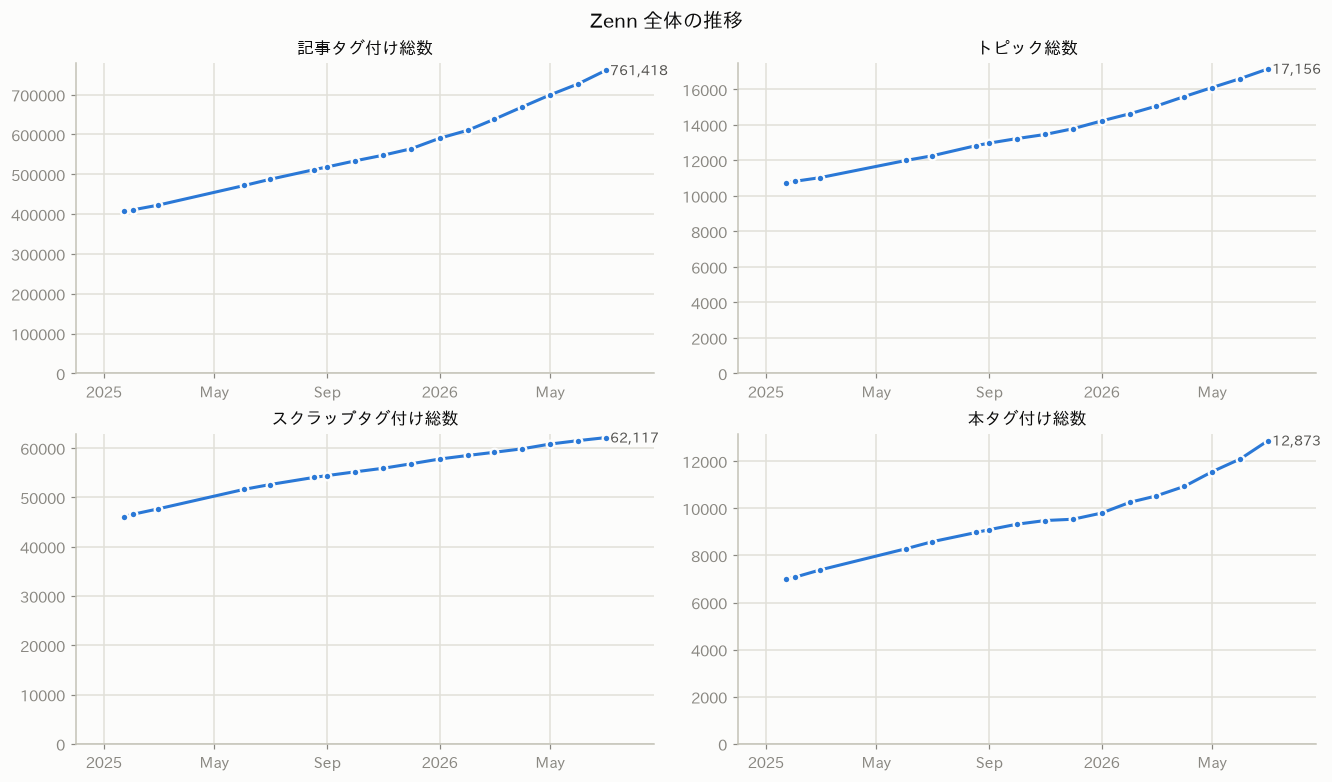

In [7]:
totals = {
    "記事タグ付け総数": articles.sum(axis=1),
    "トピック総数": articles.notna().sum(axis=1),
    "スクラップタグ付け総数": scraps.sum(axis=1),
    "本タグ付け総数": books.sum(axis=1),
}

yr = snapshot_at(12)
for label, s in totals.items():
    print(f"{label}: {s.loc[yr]:,.0f} → {s.iloc[-1]:,.0f}（直近12ヶ月 {(s.iloc[-1] / s.loc[yr] - 1) * 100:+.1f}%）")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, (label, s) in zip(axes.flat, totals.items()):
    ax.plot(s.index, s.values, color=SERIES[0],
            marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.annotate(f" {s.iloc[-1]:,.0f}", (s.index[-1], s.iloc[-1]),
                color=INK2, fontsize=9, va="center")
    ax.set_title(label, fontsize=11)
    ax.set_ylim(bottom=0)
    locator = mdates.AutoDateLocator(maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.margins(x=0.1)
fig.suptitle("Zenn 全体の推移", fontsize=13)
plt.show()


### 定番トピックの現在地 — 記事数 Top 20

最大勢力の顔ぶれと、その中での勢いの差（シェア・成長率・順位変動）。
タグ統合は1章で補正済み。それでも順位変動が極端に大きいものは未検出の統合を疑い、`detect_tag_merges()` で確認する。


In [8]:
def top_topics_table(n: int = 20, months_back: int = 12) -> pd.DataFrame:
    """最新の記事数 Top N の詳細（シェア・成長率・順位変動）。"""
    latest, prev_date = articles.iloc[-1], snapshot_at(months_back)
    prev = articles.loc[prev_date]
    rank_now, rank_prev = latest.rank(ascending=False), prev.rank(ascending=False)
    d1 = articles.index[-2]
    recent = (latest - articles.loc[d1]) / (articles.index[-1] - d1).days
    top = latest.nlargest(n)
    move = (rank_prev - rank_now).reindex(top.index)
    df = pd.DataFrame({
        "トピック": display_names.reindex(top.index),
        "記事数": top.astype(int),
        "シェア%": (top / latest.sum() * 100).round(2),
        f"{months_back}ヶ月成長%": ((latest / prev - 1) * 100).reindex(top.index).round(1),
        "増加/日(直近)": recent.reindex(top.index).round(1),
        "順位変動": ["→" if pd.isna(v) or v == 0 else (f"↑{int(v)}" if v > 0 else f"↓{int(-v)}")
                  for v in move],
    })
    df.index = pd.RangeIndex(1, n + 1, name="順位")
    df.attrs["period"] = f"成長率・順位変動は {prev_date:%Y-%m-%d} 比"
    return df


top20 = top_topics_table(20)
print(top20.attrs["period"])
top20


成長率・順位変動は 2025-07-01 比


,トピック,記事数,シェア%,12ヶ月成長%,増加/日(直近),順位変動
順位,,,,,,
1,AI,19443,2.55,292.6,74.3,↑7
2,Python,16209,2.13,43.3,23.2,↓1
3,AWS,15958,2.10,45.5,15.2,↓1
4,TypeScript,12778,1.68,35.5,13.4,↓1
5,React,10766,1.41,24.2,6.5,↓1
6,JavaScript,10187,1.34,18.9,6.4,↓1
7,大規模言語モデル,8456,1.11,143.0,30.7,↑9
8,Next.js,8105,1.06,33.4,6.3,↓2
9,Claude Code,7551,0.99,1737.2,30.7,↑156


### 現 Top 10 の順位推移 — 誰が上がり、誰が押し下げられたか

最新の記事数 Top 10 について、全期間の順位（記事数ランク）の遷移を追う。
大きく順位を上げたトピックに色を付け、他はグレー。圏外（下限より下）から入ってくる線は途中から現れる。


findfont: Failed to find font weight bold, now using 400.


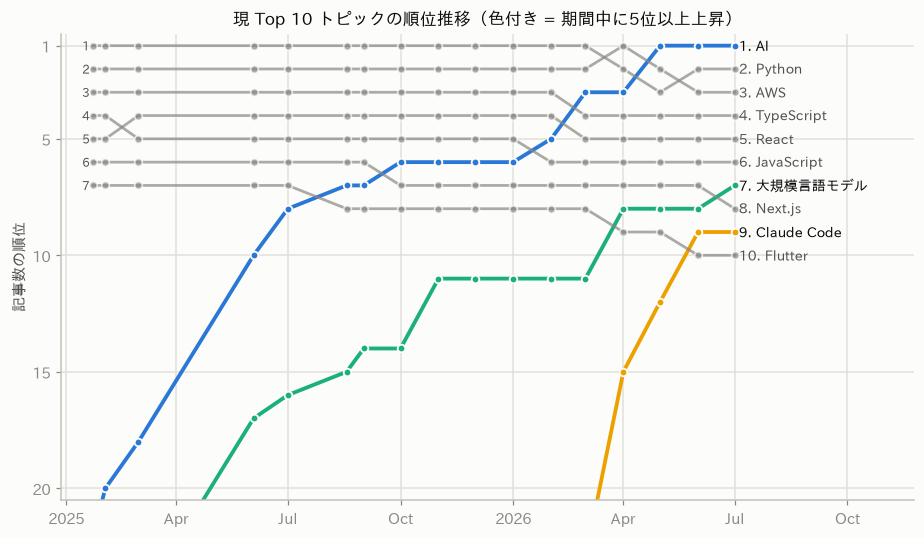

In [9]:
def plot_rank_bump(n: int = 10, ylim: int = 20, mover_threshold: int = 5) -> None:
    """最新 Top N トピックの順位推移バンプチャート。

    期間中に mover_threshold 以上順位を上げたトピックをアクセント色で強調する。
    """
    latest_top = articles.iloc[-1].nlargest(n).index
    ranks = articles.rank(axis=1, ascending=False, method="min")[latest_top]
    movers = [t for t in latest_top if ranks[t].max() - ranks[t].iloc[-1] >= mover_threshold]
    mover_colors = {t: SERIES[i % len(SERIES)] for i, t in enumerate(movers)}

    fig, ax = plt.subplots(figsize=(10, 5.5))
    for t in latest_top:
        r = ranks[t].dropna()
        color = mover_colors.get(t, MUTED)
        is_mover = t in mover_colors
        ax.plot(r.index, r.values, color=color, linewidth=2.5 if is_mover else 1.8,
                alpha=1.0 if is_mover else 0.7,
                marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2)
        ax.annotate(f" {int(r.iloc[-1])}. {display_names.get(t, t)}",
                    (r.index[-1], r.iloc[-1]), color=INK if is_mover else INK2,
                    fontsize=9, va="center", fontweight="bold" if is_mover else "normal")
        if r.iloc[0] <= ylim:  # 期初から圏内のトピックは開始順位も示す
            ax.annotate(f"{int(r.iloc[0])} ", (r.index[0], r.iloc[0]),
                        color=INK2, fontsize=8, va="center", ha="right")

    ax.set_ylim(ylim + 0.5, 0.5)  # 上が1位
    ax.set_yticks([1, 5, 10, 15, 20])
    ax.set_ylabel("記事数の順位")
    ax.set_xlim(right=ranks.index[-1] + pd.Timedelta(days=int((ranks.index[-1] - ranks.index[0]).days * 0.28)))
    locator = mdates.AutoDateLocator(maxticks=10)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_title(f"現 Top {n} トピックの順位推移（色付き = 期間中に{mover_threshold}位以上上昇）", fontsize=11)
    plt.show()


plot_rank_bump()


### 現 Top 10 の記事数と増加ペース

同じ Top 10 を絶対数でも見る。上：記事数の推移、下：増加ペース（間隔が不均一なので1日あたりに正規化。概ね「月ごとの増加量」の感覚で読める）。
色の意味はバンプチャートと同じ（色付き = 期間中に大きく順位を上げたトピック）。
増加ペースでは、改名・統合による人工的なジャンプ（1区間で記事数3倍超）は欠損として除いてある。


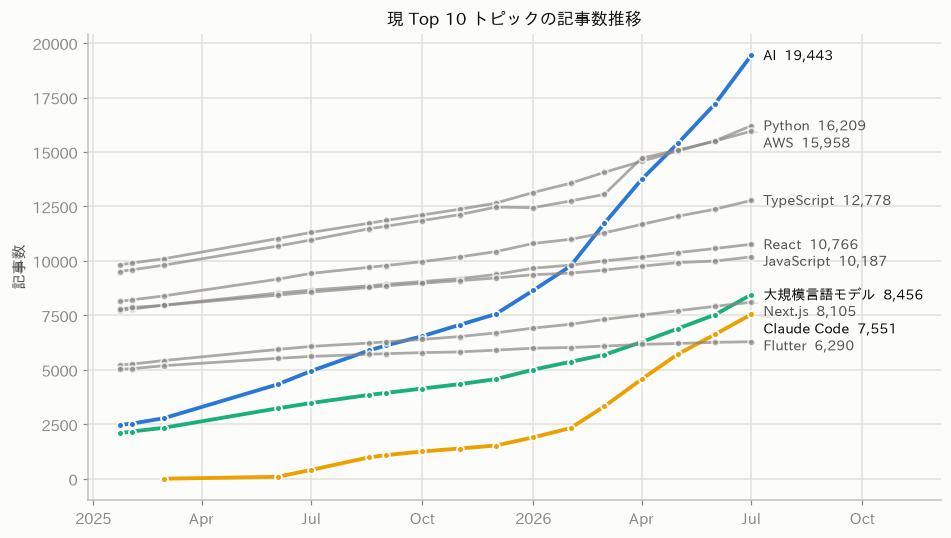

In [10]:
def plot_top_lines(n: int = 10, rate: bool = False, mover_threshold: int = 5,
                   title: str | None = None) -> None:
    """最新 Top N トピックの記事数（rate=True で増加ペース/日）の推移。

    バンプチャートと同じ基準で順位を大きく上げたトピックを強調し、
    凡例の代わりに右端へ直接ラベル（衝突は縦にずらして回避）する。
    """
    latest_top = articles.iloc[-1].nlargest(n).index
    ranks = articles.rank(axis=1, ascending=False, method="min")[latest_top]
    movers = [t for t in latest_top if ranks[t].max() - ranks[t].iloc[-1] >= mover_threshold]
    mover_colors = {t: SERIES[i % len(SERIES)] for i, t in enumerate(movers)}

    sub = articles[list(latest_top)]
    if rate:
        ratio = sub / sub.shift()
        sub = sub.diff().div(sub.index.to_series().diff().dt.days, axis=0)
        sub = sub.mask(ratio > 3)  # 改名・統合による人工的なジャンプ（1区間で3倍超）は欠損扱い

    # ラベルの縦位置: 値の大きい順に最小間隔で押し下げ、床を割ったら押し戻す（衝突回避）
    finals = sub.apply(lambda c: c.dropna().iloc[-1]).sort_values(ascending=False)
    gap = (finals.max() - min(0, finals.min())) * 0.04
    ys = list(finals.values)
    for i in range(1, len(ys)):
        ys[i] = min(finals.iloc[i], ys[i - 1] - gap)
    floor = min(0, finals.min())
    if ys and ys[-1] < floor:
        ys[-1] = floor
        for i in range(len(ys) - 2, -1, -1):
            ys[i] = max(ys[i], ys[i + 1] + gap)
    label_y = dict(zip(finals.index, ys))

    fig, ax = plt.subplots(figsize=(10, 5.5))
    x_pad = pd.Timedelta(days=10)
    for t in latest_top:
        s = sub[t].dropna()
        color, is_mover = mover_colors.get(t, MUTED), t in mover_colors
        ax.plot(s.index, s.values, color=color, linewidth=2.5 if is_mover else 1.8,
                alpha=1.0 if is_mover else 0.7,
                marker="o", markersize=4.5, markeredgecolor=SURFACE, markeredgewidth=1.2)
        y_end = s.iloc[-1]
        moved = abs(label_y[t] - y_end) > gap * 0.3
        ax.annotate(f"{display_names.get(t, t)}  {y_end:,.1f}" if rate else f"{display_names.get(t, t)}  {y_end:,.0f}",
                    xy=(s.index[-1], y_end), xytext=(s.index[-1] + x_pad, label_y[t]),
                    textcoords="data", fontsize=9, va="center",
                    color=INK if is_mover else INK2,
                    fontweight="bold" if is_mover else "normal",
                    arrowprops={"arrowstyle": "-", "color": GRID, "lw": 1} if moved else None)

    ax.set_ylabel("増加数/日" if rate else "記事数")
    ax.set_ylim(bottom=min(0, ax.get_ylim()[0]),
                top=max(ax.get_ylim()[1], max(label_y.values()) + gap))
    ax.set_xlim(right=sub.index[-1] + pd.Timedelta(days=int((sub.index[-1] - sub.index[0]).days * 0.3)))
    locator = mdates.AutoDateLocator(maxticks=10)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_title(title or (f"現 Top {n} トピックの増加ペース" if rate else f"現 Top {n} トピックの記事数推移"), fontsize=11)
    plt.show()


plot_top_lines()


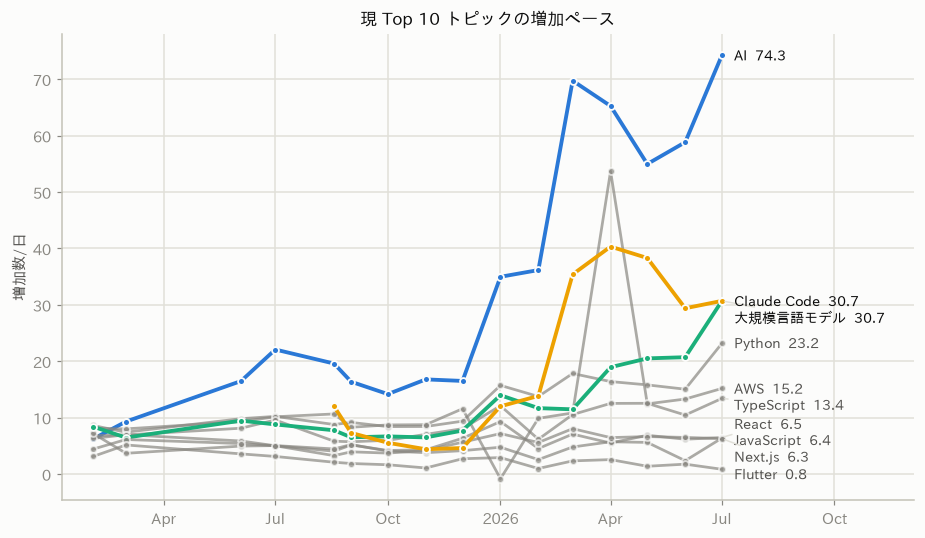

In [11]:
plot_top_lines(rate=True)


### 関心は集中しているか — 上位トピックへの集中度

上位 10 / 50 / 100 トピックの合計が全タグ付けに占める割合。
上がっていれば少数の話題への一極集中、下がっていればロングテール化（話題の多様化）。


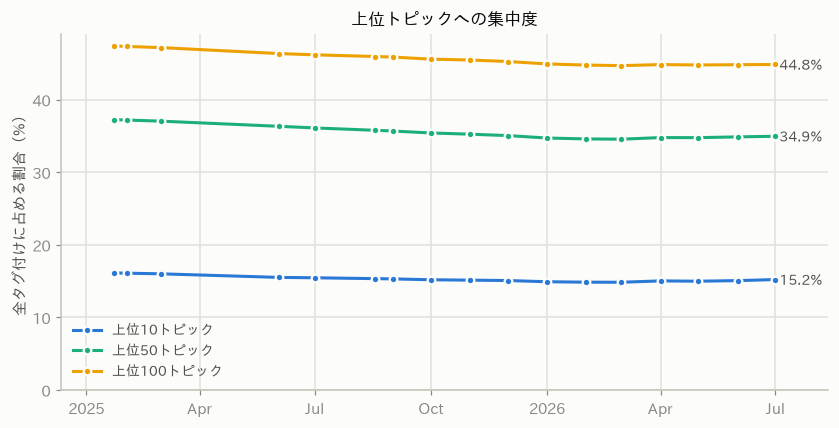

In [12]:
total_articles = articles.sum(axis=1)
conc = pd.DataFrame({
    f"上位{n}トピック": articles.apply(lambda row: row.nlargest(n).sum(), axis=1) / total_articles * 100
    for n in (10, 50, 100)
})

fig, ax = plt.subplots(figsize=(9, 4.2))
for color, (label, s) in zip(SERIES, conc.items()):
    ax.plot(s.index, s.values, color=color, label=label,
            marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.annotate(f" {s.iloc[-1]:.1f}%", (s.index[-1], s.iloc[-1]),
                color=INK2, fontsize=9, va="center")
ax.legend(frameon=False, labelcolor=INK2, fontsize=9)
ax.set_ylabel("全タグ付けに占める割合（%）")
ax.set_ylim(bottom=0)
locator = mdates.AutoDateLocator(maxticks=10)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.margins(x=0.08)
ax.set_title("上位トピックへの集中度", fontsize=11)
plt.show()


> 📌 **読みどころ（2026-07時点）** — 全指標が右肩上がりで減速の気配はない。記事は直近12ヶ月で +56% と加速中。
> 本（+50%）も2026年から伸びが立ち上がった。スクラップ（+18%）だけ相対的に緩やか。
> Top 20 では **AI が Python を抜いて首位に**（12ヶ月で 8位→1位）。Claude Code（↑156）と Claude（↑55）が急浮上し、
> 大規模言語モデルもタグ統合補正後の実質値で +143%（16位→7位）と伸びている。
> 集中度は上位10トピックで 16.1% → 15.2% と2025年を通じて緩やかに低下（ロングテール化）してきたが、
> **2026年に入って AI 系メガトピックの伸びで下げ止まり、わずかに再集中**に転じている点に注目。


## 3. 何が伸びているか

### 急上昇 Top 15（直近1ヶ月）

絶対数で最も記事が増えたトピック。`rising_ranking(months_back=...)` で期間変更、`ascending=True` で下降側も見られる（下降は改名・削除の検出に有効）。


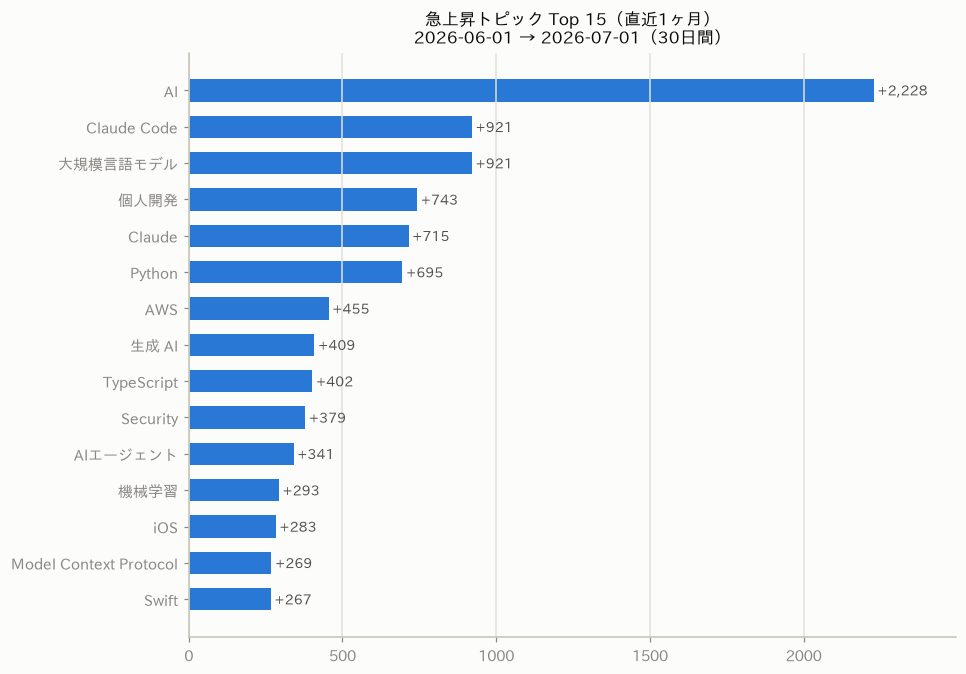

In [13]:
plot_ranking(rising_ranking(months_back=1, top_n=15), "急上昇トピック Top 15（直近1ヶ月）")


### 成長ランドスケープ — 規模 × 成長率で俯瞰する

絶対数のランキングは大型トピックが、成長率のランキングは小型トピックが有利になる。
散布図なら **規模（横軸・対数）と成長率（縦軸）を同時に** 見られて、どの規模帯で何が伸びているかが一枚でわかる。
AI 関連（1章のヒューリスティックで判定）を色分けしてある。

数表が必要なときは `growth_ranking(months_back, min_start)`。


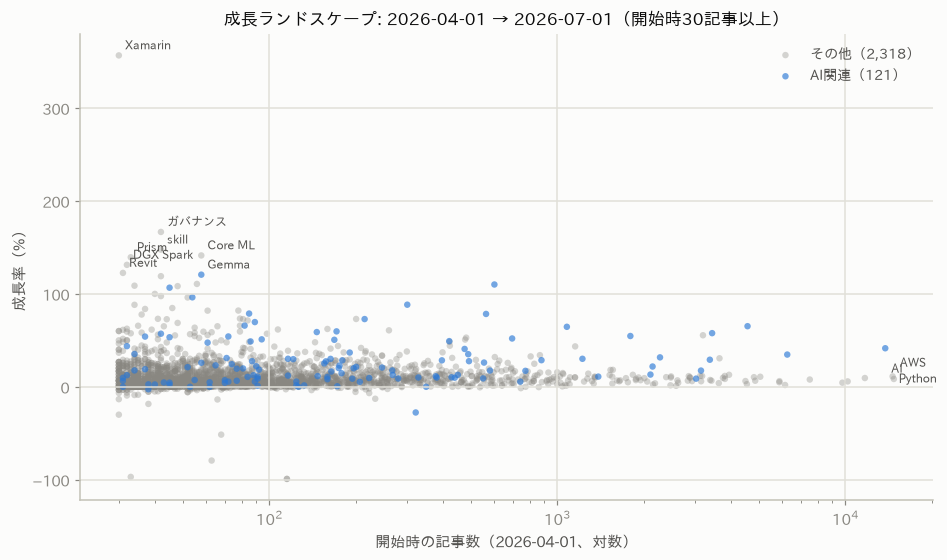

In [14]:
def plot_growth_landscape(months_back: int | None = 3, min_start: int = 30, annotate_n: int = 8) -> None:
    """規模（開始時記事数）× 成長率の散布図。高成長トピックの分布を俯瞰する。"""
    start_date, end_date = snapshot_at(months_back), articles.index[-1]
    start, end = articles.loc[start_date], articles.loc[end_date]
    mask = (start >= min_start) & end.notna()
    g = pd.DataFrame({"開始時": start[mask], "成長率": ((end - start) / start * 100)[mask]}).dropna()
    g["ai"] = [looks_ai(t) for t in g.index]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    for is_ai, color, alpha, label in [(False, MUTED, 0.35, "その他"), (True, SERIES[0], 0.65, "AI関連")]:
        part = g[g["ai"] == is_ai]
        ax.scatter(part["開始時"], part["成長率"], s=18, color=color, alpha=alpha,
                   label=f"{label}（{len(part):,}）", edgecolors="none")
    growth_top = g.nlargest(annotate_n, "成長率")
    for t, row in growth_top.iterrows():
        ax.annotate(display_names.get(t, t), (row["開始時"], row["成長率"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=8, color=INK2)
    size_top = g.nlargest(3, "開始時").drop(growth_top.index, errors="ignore")
    for i, (t, row) in enumerate(size_top.iterrows()):
        # 大型トピックは x が近接しやすいのでラベルを縦にずらす
        ax.annotate(display_names.get(t, t), (row["開始時"], row["成長率"]),
                    xytext=(4, 8 - 12 * i), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_xscale("log")
    ax.set_xlabel(f"開始時の記事数（{start_date:%Y-%m-%d}、対数）")
    ax.set_ylabel("成長率（%）")
    ax.set_title(f"成長ランドスケープ: {start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}"
                 f"（開始時{min_start}記事以上）", fontsize=11)
    ax.legend(frameon=False, labelcolor=INK2, fontsize=9)
    plt.show()


plot_growth_landscape(months_back=3)


### 規模帯別サマリ — 散布図の数表版

規模帯ごとの成長率の分布。中央値で「その規模帯の普通の成長」、上位10%で「勝ち組の成長」がわかる。


In [15]:
def size_band_summary(months_back: int | None = 3, min_start: int = 30) -> pd.DataFrame:
    """規模帯（開始時記事数）ごとの成長率分布のサマリ。"""
    start_date, end_date = snapshot_at(months_back), articles.index[-1]
    start, end = articles.loc[start_date], articles.loc[end_date]
    g = ((end - start) / start * 100)[(start >= min_start) & end.notna()].dropna()
    bands = pd.cut(start.reindex(g.index), [min_start, 100, 300, 1000, 3000, float("inf")],
                   labels=[f"{min_start}〜100", "100〜300", "300〜1,000", "1,000〜3,000", "3,000+"],
                   include_lowest=True)
    rows = []
    for band, grp in g.groupby(bands, observed=True):
        top3 = grp.nlargest(3).index
        rows.append({
            "規模帯（開始時記事数）": band,
            "トピック数": len(grp),
            "成長率 中央値%": round(grp.median(), 1),
            "成長率 上位10%": round(grp.quantile(0.9), 1),
            "成長トップ3": "、".join(display_names.get(t, t) for t in top3),
        })
    out = pd.DataFrame(rows).set_index("規模帯（開始時記事数）")
    out.attrs["period"] = f"{start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}"
    return out


bands = size_band_summary(months_back=3)
print(bands.attrs["period"])
bands


2026-04-01 → 2026-07-01


,トピック数,成長率 中央値%,成長率 上位10%,成長トップ3
規模帯（開始時記事数）,,,,
30〜100,1570,7.1,27.0,Xamarin、ガバナンス、skill
100〜300,556,8.2,26.1,Skills、マルチエージェント、Mastra
"300〜1,000",221,9.6,26.1,Codex、ローカル LLM、Anthropic
"1,000〜3,000",59,9.5,19.0,Agent、AIエージェント、設計
"3,000+",33,9.4,40.1,Claude Code、Claude、個人開発


### 加速・失速 — 直近でペースが変わったトピック

直近の区間とその前の区間で「1日あたり増加数」を比較する。急上昇ランキングより早くトレンドの転換を捉えられる。
改名・削除によるゼロ化ノイズを避けるため、一定の活動量（min_rate /日）があるトピックに絞る。
数表は `momentum_ranking()`。


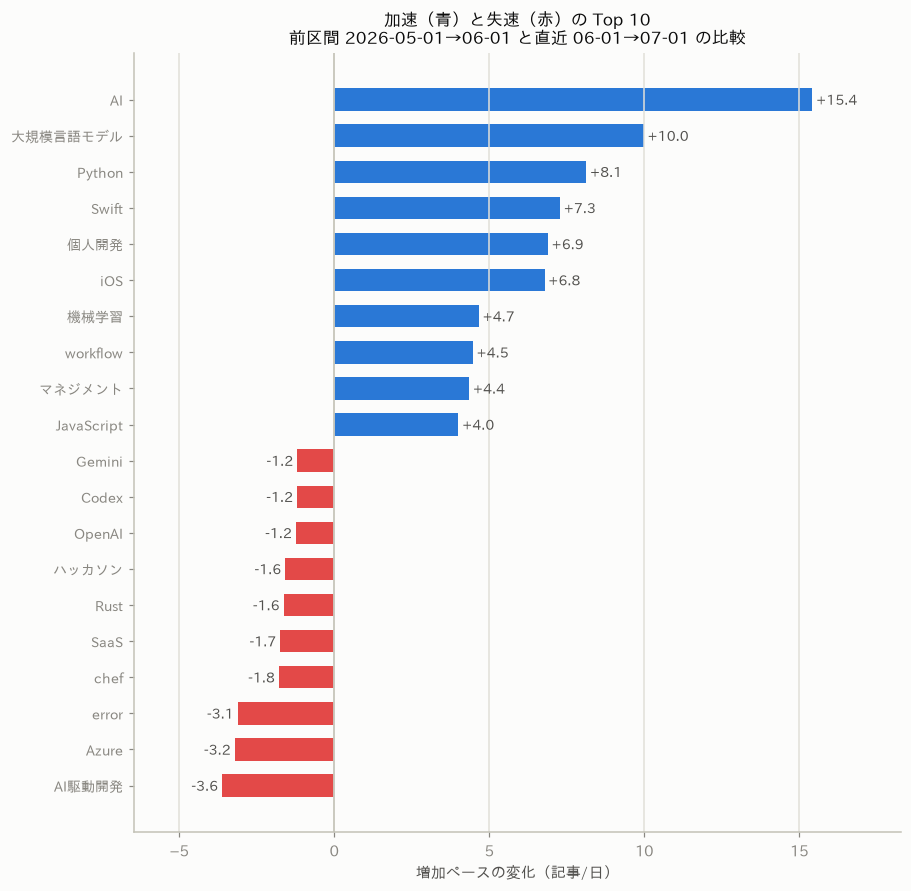

In [16]:
def plot_momentum(top_n: int = 10, min_rate: float = 0.5) -> None:
    """加速・失速トピックを発散バーで表示する。

    加速側は直近ペースが、失速側は前区間ペースが min_rate /日 以上のトピックに限定して
    改名・削除によるゼロ化ノイズを除く。
    """
    d0, d1, d2 = articles.index[-3], articles.index[-2], articles.index[-1]
    rate_prev = (articles.loc[d1] - articles.loc[d0]) / (d1 - d0).days
    rate_now = (articles.loc[d2] - articles.loc[d1]) / (d2 - d1).days
    accel = (rate_now - rate_prev).dropna()
    up = accel[rate_now.reindex(accel.index) >= min_rate].nlargest(top_n)
    down = accel[rate_prev.reindex(accel.index) >= min_rate].nsmallest(top_n)
    sel = pd.concat([down, up]).sort_values()

    fig, ax = plt.subplots(figsize=(9, 0.38 * len(sel) + 1.6))
    y = range(len(sel))
    colors = [DIVERGE_UP if v >= 0 else DIVERGE_DOWN for v in sel]
    bars = ax.barh(y, sel.values, color=colors, height=0.62)
    ax.bar_label(bars, labels=[f" {v:+.1f} " for v in sel.values], color=INK2, fontsize=9)
    ax.set_yticks(y, [display_names.get(t, t) for t in sel.index], fontsize=9)
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("増加ペースの変化（記事/日）")
    ax.set_title(f"加速（青）と失速（赤）の Top {top_n}\n"
                 f"前区間 {d0:%Y-%m-%d}→{d1:%m-%d} と直近 {d1:%m-%d}→{d2:%m-%d} の比較", fontsize=11)
    ax.margins(x=0.15)
    plt.show()


plot_momentum()


### 新規登場 — この半年で生まれたトピック

新しい技術・サービスの登場を捉える。`newcomer_ranking(months_back)` で期間変更。


In [17]:
new_6m = newcomer_ranking(months_back=6, top_n=10)
print(new_6m.attrs["period"])
new_6m


2026-01-01 以降に初登場


,トピック,初登場,最新記事数
name,,,
openclaw,OpenClaw,2026-02,341
gch4,gch4,2026-02,175
ハーネスエンジニアリング,ハーネスエンジニアリング,2026-03,134
gemma4,Gemma 4,2026-05,72
amivoice,AmiVoice,2026-06,70
社内研修,社内研修,2026-05,68
agentteams,Agent teams,2026-03,63
bluecode,bluecode,2026-05,62
cowork,Cowork,2026-02,57


> 📌 **読みどころ（2026-07時点）** — 急上昇 Top 15 は AI・Claude Code・大規模言語モデル・個人開発と AI 関連がほぼ独占。
> ランドスケープでは高成長帯（+50%超）の大半が青（AI関連）で、非AI の高成長は個人開発・エッセイなど文化系が中心。
> 規模帯別に見ると成長率の中央値はどの帯も 7〜10% で大差ない一方、**3,000記事超の帯だけ上位10%が +40% と突出**——
> 大型トピックは普通停滞するはずが、AI 系メガトピックが例外的に伸びていることを示す。
> 加速側には Swift / iOS（WWDC 効果とみられる）、失速側には AI駆動開発・Azure が入った。
> 新規登場では OpenClaw（2026-02 初登場で 341 記事）が突出。


## 4. AI の牽引力 — 成長のどれだけが AI か

1章のヒューリスティックで全トピックを AI / 非AI に二分し、タグ付け数を比較する。
まず判定結果の上位を確認してから（誤検出があれば `AI_KEYWORDS` を調整）、全体を集計する。


In [18]:
# 判定の妥当性確認: AI関連と判定されたトピックの上位15
pd.DataFrame({
    "トピック": display_names.reindex(ai_topics),
    "最新記事数": articles.iloc[-1].reindex(ai_topics).fillna(0).astype(int),
}).sort_values("最新記事数", ascending=False).head(15)


,トピック,最新記事数
name,,
ai,AI,19443
大規模言語モデル,大規模言語モデル,8456
claudecode,Claude Code,7551
claude,Claude,5431
生成ai,生成 AI,4366
機械学習,機械学習,3700
chatgpt,ChatGPT,3295
mcp,Model Context Protocol,2989
aiエージェント,AIエージェント,2770


最新のタグ付け数: AI 97,432 / 非AI 663,986（累計シェア 12.8% ← 期初 5.0%）
全期間の増加分: AI 77,041 / 非AI 277,778


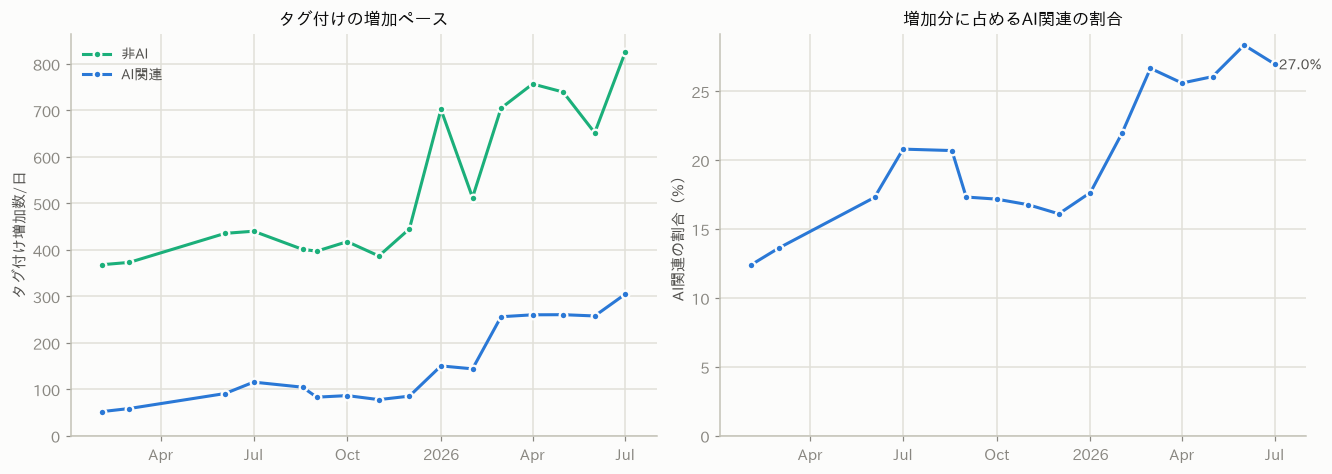

In [19]:
ai_total = articles[ai_topics].sum(axis=1)
nonai_total = articles.sum(axis=1) - ai_total

days = articles.index.to_series().diff().dt.days
ai_rate, nonai_rate = ai_total.diff() / days, nonai_total.diff() / days
growth_share = (ai_total.diff() / (ai_total.diff() + nonai_total.diff()) * 100).dropna()
cum_share = ai_total / (ai_total + nonai_total) * 100

print(f"最新のタグ付け数: AI {ai_total.iloc[-1]:,.0f} / 非AI {nonai_total.iloc[-1]:,.0f}"
      f"（累計シェア {cum_share.iloc[-1]:.1f}% ← 期初 {cum_share.iloc[0]:.1f}%）")
print(f"全期間の増加分: AI {ai_total.iloc[-1] - ai_total.iloc[0]:,.0f} /"
      f" 非AI {nonai_total.iloc[-1] - nonai_total.iloc[0]:,.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")

for s, label, color in [(nonai_rate.dropna(), "非AI", SERIES[1]), (ai_rate.dropna(), "AI関連", SERIES[0])]:
    ax1.plot(s.index, s.values, color=color, label=label,
             marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax1.legend(frameon=False, labelcolor=INK2, fontsize=9)
ax1.set_ylabel("タグ付け増加数/日")
ax1.set_ylim(bottom=0)
ax1.set_title("タグ付けの増加ペース", fontsize=11)

ax2.plot(growth_share.index, growth_share.values, color=SERIES[0],
         marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax2.annotate(f" {growth_share.iloc[-1]:.1f}%", (growth_share.index[-1], growth_share.iloc[-1]),
             color=INK2, fontsize=9, va="center")
ax2.set_ylabel("AI関連の割合（%）")
ax2.set_ylim(bottom=0)
ax2.set_title("増加分に占めるAI関連の割合", fontsize=11)

for ax in (ax1, ax2):
    locator = mdates.AutoDateLocator(maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.margins(x=0.06)
plt.show()


### 定番トピックとのシェア比較

「Zenn 全体のタグ付けに占める割合」で AI と定番トピックの相対的な人気を比べる。
シェアが下がっていても絶対数は増えていることが多い点に注意。


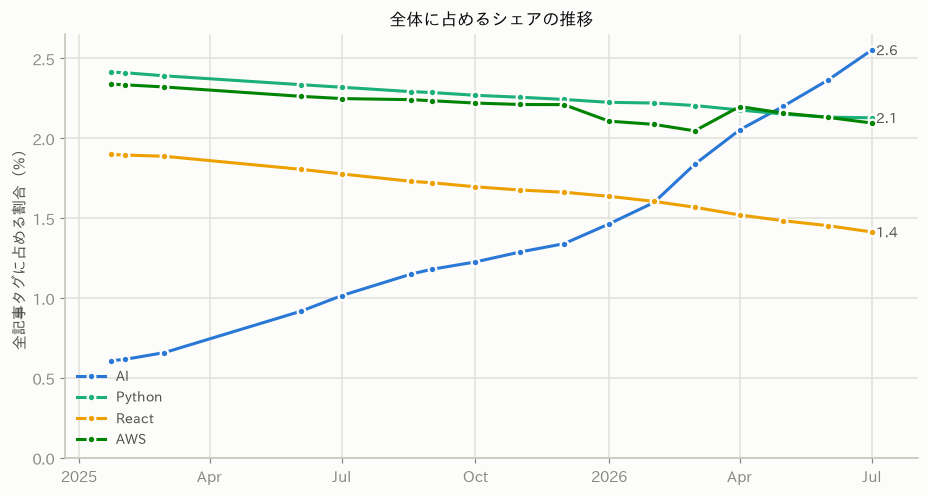

In [20]:
share = articles.div(articles.sum(axis=1), axis=0) * 100
plot_topics(["ai", "python", "react", "aws"], metric=share,
            ylabel="全記事タグに占める割合（%）", title="全体に占めるシェアの推移")


### AI の中の勢力図


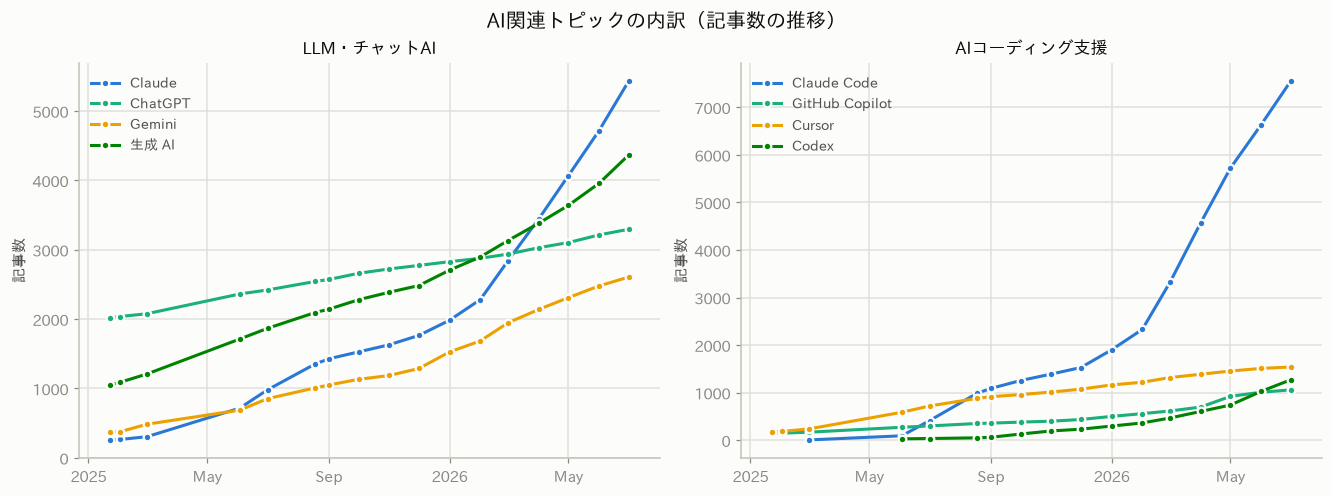

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
plot_topics(["claude", "chatgpt", "gemini", "生成ai"], ax=axes[0], title="LLM・チャットAI")
plot_topics(["claudecode", "githubcopilot", "cursor", "codex"], ax=axes[1], title="AIコーディング支援")
fig.suptitle("AI関連トピックの内訳（記事数の推移）", fontsize=13)
plt.show()


> 📌 **読みどころ（2026-07時点）** — AI 関連の累計シェアは 5.0% → 12.8%、**新規タグ付けの 27% が AI 関連**まで拡大し、
> シェア推移では `ai` 単独トピックが Python・React を追い抜いた。
> 内訳では 2026年2月頃に Claude Code が ChatGPT を、Claude 本体も生成 AI を追い抜き、コーディング支援では
> Claude Code（7,551）が Cursor / Copilot（約1,000〜1,500）を大きく引き離している。


## 5. ケーススタディ — テーマ別比較

比較の基本形は `compare_topics([...])`: **左に絶対数（規模感）、右に相対成長（勢いの公平な比較）**。
右パネルは全トピックが20記事以上になった時点を100とした指数で、開きが極端なときは対数軸になる。
以下は3つのテーマの例。トピックのリストを差し替えれば任意のテーマで再利用できる。


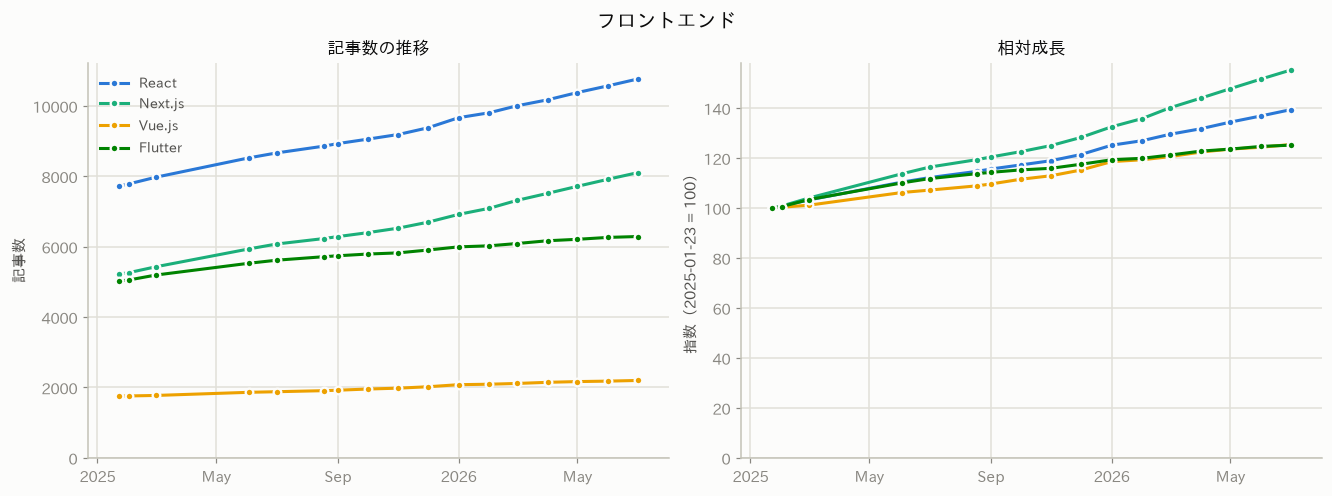

In [22]:
compare_topics(["react", "nextjs", "vue", "flutter"], title="フロントエンド")


### 開発環境・パッケージ管理

Nix・mise など「宣言的・再現可能な環境構築」の新世代と、Homebrew・asdf など定番の対比。


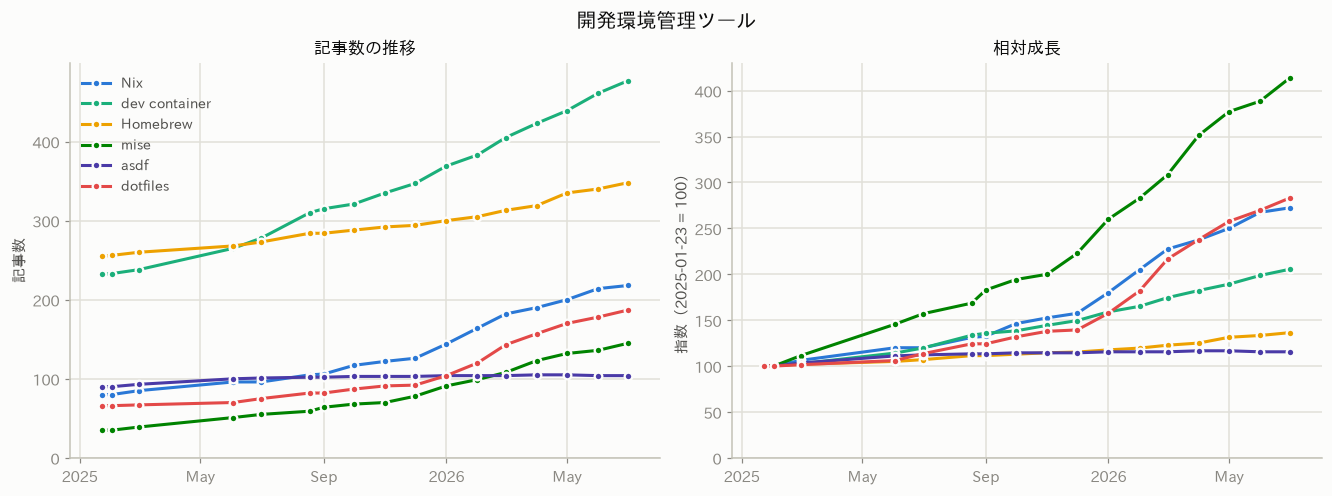

In [23]:
compare_topics(["nix", "devcontainer", "homebrew", "mise", "asdf", "dotfiles"],
               title="開発環境管理ツール")


### ネイティブアプリ開発

OS ネイティブ系とクロスプラットフォーム系。後者は規模差が大きい（Flutter 6,000超 〜 Tauri 300弱）ので右の相対成長パネルが効く。


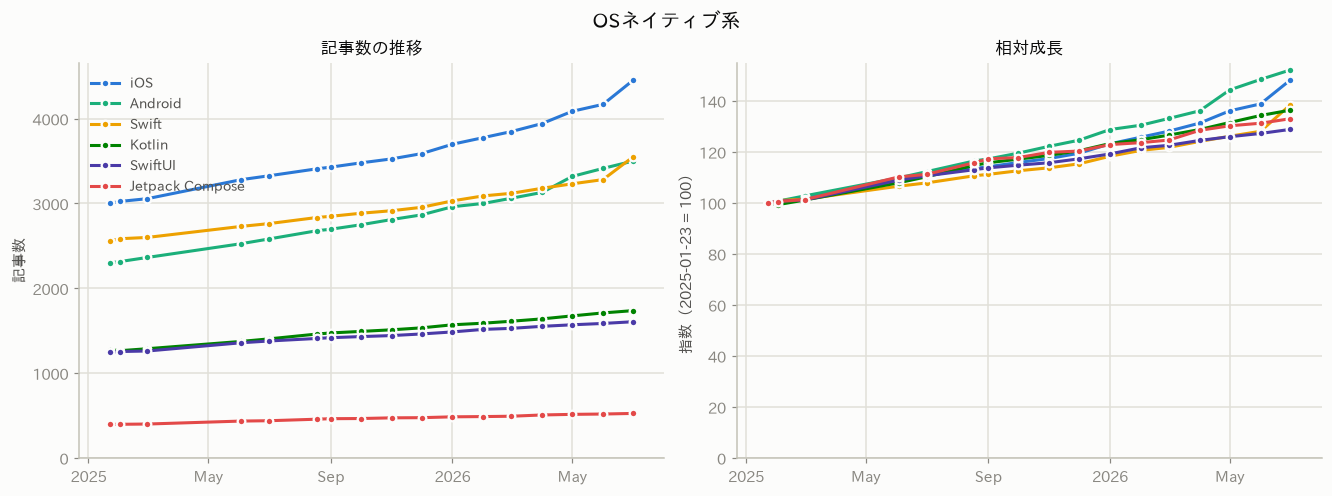

In [24]:
compare_topics(["ios", "android", "swift", "kotlin", "swiftui", "jetpackcompose"],
               title="OSネイティブ系")


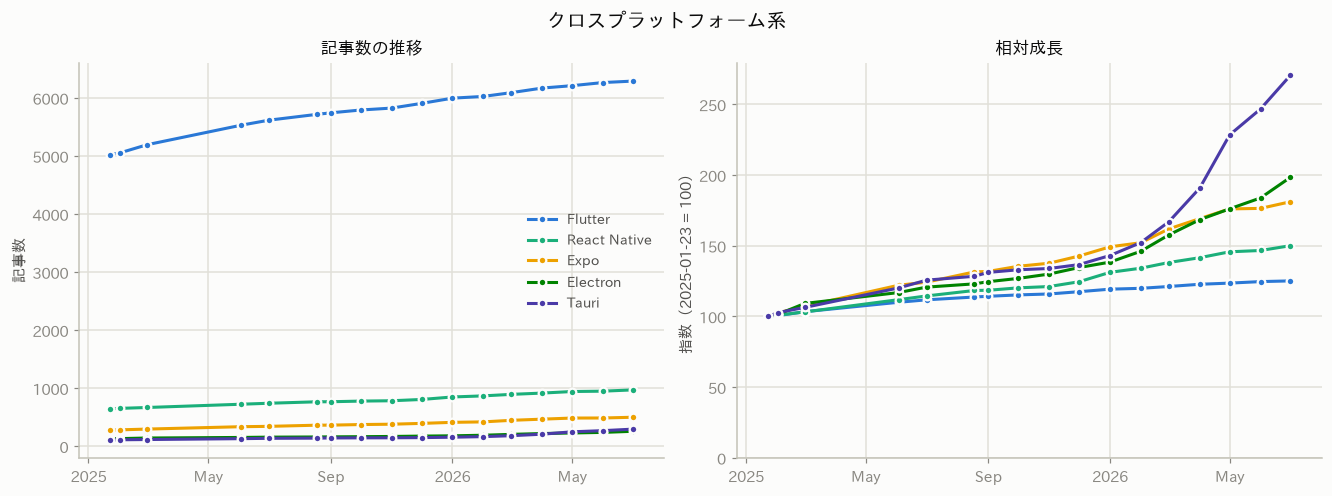

In [25]:
compare_topics(["flutter", "reactnative", "expo", "electron", "tauri"],
               title="クロスプラットフォーム系")


### 言語・クラウド（概観）


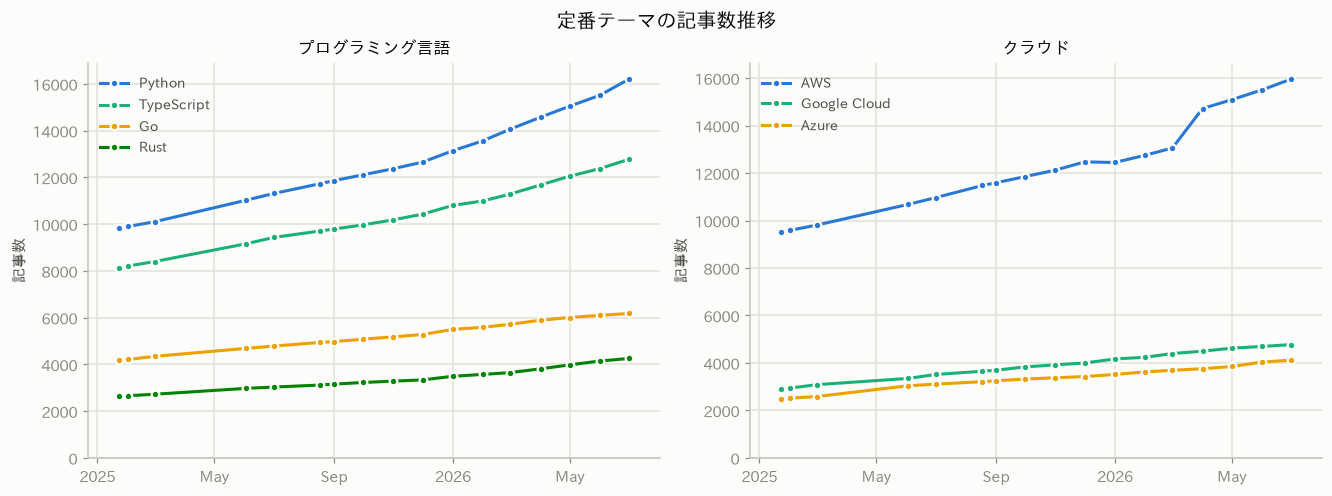

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
plot_topics(["python", "typescript", "go", "rust"], ax=axes[0], title="プログラミング言語")
plot_topics(["aws", "googlecloud", "azure"], ax=axes[1], title="クラウド")
fig.suptitle("定番テーマの記事数推移", fontsize=13)
plt.show()


> 📌 **読みどころ（2026-07時点）** — 環境構築では mise（+314%）と Nix（+173%）が伸び、asdf（+16%）は停滞して世代交代が見える。
> ネイティブアプリは率では Tauri（+171%）などデスクトップ系が首位で、最大勢力の Flutter（+25%）は減速。
> OS ネイティブ（iOS +48% / Android +52%）は堅調で、直近は WWDC 時期に iOS・Swift がスパイクした。
> 言語・クラウドは Python / AWS が首位のまま緩やかに拡大している。


## 6. ヒートマップ — 各トピックはいつ盛り上がったか

トピック × 期間で増加ペース（/日）を表示する。各行はそのトピックのピーク = 1 に正規化してあるので、
**色の濃い場所 = そのトピックが最も盛り上がった時期**。空白は未登場の期間。
時系列の折れ線では埋もれる「盛り上がりのタイミングの違い」が一覧できる。


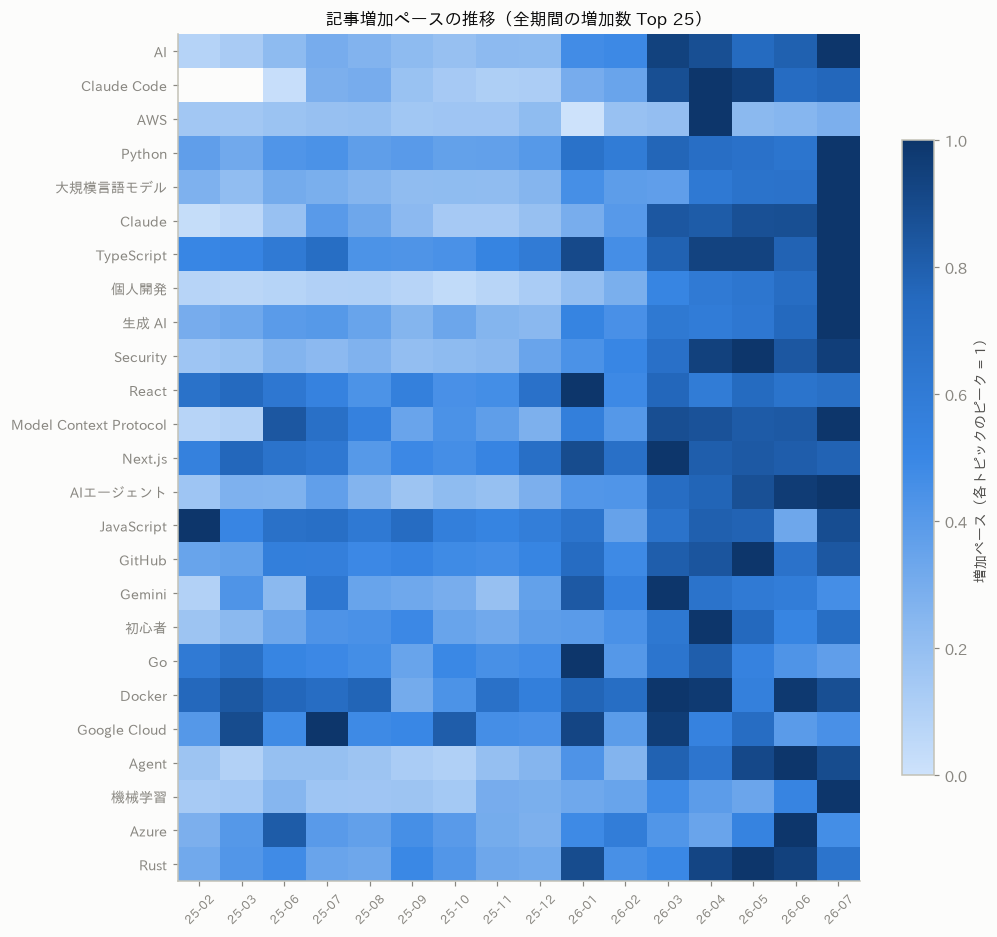

In [27]:
def plot_growth_heatmap(topics: list[str] | None = None, top_n: int = 25) -> None:
    """トピック × 期間の増加ペースをヒートマップ表示（各行はピーク=1に正規化）。"""
    rate = articles.diff().div(articles.index.to_series().diff().dt.days, axis=0).iloc[1:]
    if topics is None:  # 指定がなければ全期間の増加数 Top N
        total = (articles.iloc[-1] - articles.iloc[0].fillna(0)).dropna()
        topics = total.sort_values(ascending=False).head(top_n).index.tolist()
    peak = rate[topics].max()
    data = rate[topics].div(peak.where(peak > 0)).T

    fig, ax = plt.subplots(figsize=(10, 0.34 * len(topics) + 1.5))
    mesh = ax.imshow(data.values, cmap=BLUES, aspect="auto", vmin=0, vmax=1)
    ax.set_yticks(range(len(topics)), [display_names.get(t, t) for t in topics], fontsize=9)
    ax.set_xticks(range(len(rate)), [f"{d:%y-%m}" for d in rate.index],
                  fontsize=8, rotation=45)
    ax.grid(False)
    cbar = fig.colorbar(mesh, ax=ax, shrink=0.75)
    cbar.set_label("増加ペース（各トピックのピーク = 1）", fontsize=9, color=INK2)
    ax.set_title("記事増加ペースの推移（全期間の増加数 Top 25）", fontsize=11)
    plt.show()


plot_growth_heatmap()


## 7. 記事以外の指標 — スクラップ・本

`metric=` を差し替えるだけで記事以外のカウントも同じ関数で分析できる。
スクラップは作業ログ・議論なので「いま試されている技術」が記事より早く現れやすい。


In [28]:
rank_scraps = rising_ranking(months_back=3, metric=scraps, top_n=10)
print("スクラップの増加:", rank_scraps.attrs["period"])
rank_scraps


スクラップの増加: 2026-04-01 → 2026-07-01（91日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
cpp,C++,194,264,70,0.77
claudecode,Claude Code,184,240,56,0.62
rag,RAG,244,285,41,0.45
ai,AI,352,391,39,0.43
大規模言語モデル,大規模言語モデル,808,845,37,0.41
rust,Rust,859,896,37,0.41
windows,Windows,209,243,34,0.37
gemma4,Gemma 4,0,33,33,0.36
python,Python,1040,1073,33,0.36


In [29]:
rank_books = rising_ranking(months_back=None, metric=books, top_n=10)
print("本の増加:", rank_books.attrs["period"])
rank_books


本の増加: 2025-01-23 → 2026-07-01（524日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
ai,AI,62,385,323,0.62
python,Python,207,392,185,0.35
claudecode,Claude Code,0,126,126,0.24
大規模言語モデル,大規模言語モデル,13,123,110,0.21
typescript,TypeScript,157,264,107,0.20
react,React,153,233,80,0.15
claude,Claude,0,78,78,0.15
生成ai,生成 AI,12,87,75,0.14
nextjs,Next.js,125,197,72,0.14


### コンテンツ比率 — 「試されている技術」と「教材化される技術」

記事数に対するスクラップ・本の比率。母数が小さいと不安定なので記事200以上に限定する。

- **スクラップ/記事 が高い** = 記事より試行錯誤ログが先行している（まだ体系化されていない・実験段階）
- **本/記事 が高い** = 体系的な教材にまとめられやすいテーマ


In [30]:
latest_a = articles.iloc[-1]
latest_s, latest_b = scraps.iloc[-1], books.iloc[-1]
eligible = latest_a >= 200

detail = pd.DataFrame({
    "トピック": display_names.reindex(latest_a.index),
    "記事数": latest_a,
    "スクラップ数": latest_s.fillna(0),
    "本数": latest_b.fillna(0),
    "スクラップ/記事": (latest_s / latest_a).round(2),
    "本/記事": (latest_b / latest_a).round(3),
})[eligible].astype({"記事数": int, "スクラップ数": int, "本数": int})

print("スクラップ率が高いトピック（試行錯誤が先行）")
display(detail.nlargest(10, "スクラップ/記事")[["トピック", "記事数", "スクラップ数", "スクラップ/記事"]])
print("本率が高いトピック（教材化されやすい）")
display(detail.nlargest(10, "本/記事")[["トピック", "記事数", "本数", "本/記事"]])


スクラップ率が高いトピック（試行錯誤が先行）


,トピック,記事数,スクラップ数,スクラップ/記事
name,,,,
tts,TTS,206,119,0.58
remix,Remix,406,163,0.40
cloudflarepages,Cloudflare Pages,203,61,0.30
svelte,Svelte,408,117,0.29
cloudflareworkers,Cloudflare Workers,442,115,0.26
deno,Deno,653,172,0.26
読書,読書,231,60,0.26
androidstudio,Android Studio,409,97,0.24
storybook,Storybook,494,118,0.24


本率が高いトピック（教材化されやすい）


,トピック,記事数,本数,本/記事
name,,,,
line,LINE,601,58,0.097
ノーコード,ノーコード,260,25,0.096
エンジニアリング,エンジニアリング,212,20,0.094
stripe,Stripe,396,35,0.088
unrealengine,Unreal Engine,464,39,0.084
入門,入門,685,57,0.083
ue5,UE5,389,32,0.082
関数型プログラミング,関数型プログラミング,225,18,0.080
django,Django,724,50,0.069


> 📌 **読みどころ（2026-07時点）** — スクラップ率トップは TTS（0.58）・Remix（0.40）・Cloudflare 系・Zig と、
> 先端・ニッチ寄りの技術が並ぶ。本率は LINE・ノーコード・入門・Unreal Engine など、チュートリアル需要の強いテーマが上位。


## 8. 付録 — トピック検索・関数リファレンス

| 関数 | 用途 |
|---|---|
| `search_topics("キーワード")` | トピックのスラッグを探す |
| `detect_tag_merges()` | タグ統合候補の検出（人力レビュー用） |
| `apply_tag_merges(matrix)` | `TAG_MERGES` による時系列の補正 |
| `rising_ranking(months_back, ascending, metric)` | 増加数ランキング（下降・スクラップ等にも対応） |
| `growth_ranking(months_back, min_start)` | 成長率ランキング（規模フィルタ付き） |
| `momentum_ranking()` / `plot_momentum()` | 加速・失速（表 / グラフ） |
| `newcomer_ranking(months_back)` | 新規登場トピック |
| `top_topics_table(n, months_back)` | 記事数 Top N の詳細（シェア・順位変動） |
| `plot_rank_bump(n, ylim)` | 現 Top N の順位推移バンプチャート |
| `plot_top_lines(n, rate=)` | 現 Top N の記事数・増加ペースの折れ線 |
| `size_band_summary(months_back, min_start)` | 規模帯別の成長率サマリ |
| `plot_topics([...], rate=, normalize=, metric=, ax=)` | 折れ線比較 |
| `compare_topics([...])` | 絶対数＋相対成長のペア表示 |
| `plot_growth_landscape(months_back, min_start)` | 規模×成長率の散布図 |
| `plot_growth_heatmap(topics, top_n)` | 増加ペースのヒートマップ |
| `plot_ranking(rank, title)` | ランキングの横棒グラフ |


In [31]:
search_topics("gemini").head(10)


,トピック,最新記事数
name,,
gemini,Gemini,2606
geminicli,Gemini CLI,302
geminiapi,Gemini API,111
gemini3,Gemini 3,15
gemininano,Gemini Nano,11
geminipro,Gemini Pro,6
geminienterprise,geminienterprise,5
geminicodeassist,Gemini Code Assist,5
gemini20,Gemini 2.0,3
